# Model comparison

Compare popularity, logistic regression, and CatBoost on the same 50,000 customers (seed 42). Product inputs come from the previous month, and already-owned products are excluded.

| Target months | Use |
|---|---|
| October 2015–March 2016 | Fit |
| April 2016 | Select model, parameters, and buyer threshold |
| May 2016 | Final evaluation |

Try logistic regression with `C = 0.1, 1.0` and CatBoost with depth `4, 6` (150 iterations). Select the ranker by April MAP@7. The buyer classifier uses depth 4 and chooses its threshold by April F1.

[Data EDA](eda.ipynb) · [Classification EDA](classification_eda.ipynb) · [README](../README.md)

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from recommender_santander.utils import get_project_root

PROJECT_DIR = get_project_root()
report_dir = PROJECT_DIR / "reports"

## Read saved results

This notebook only reads the completed reports; opening it or running all cells does not start training.

To train explicitly, close other notebooks and run one command at a time from the project root:

```sh
uv run python train.py --customers 5000
```

The existing reports below were produced with 50,000 customers. A new training run overwrites reports and the model with its chosen sample size. Use `--customers 50000` only when you deliberately want to repeat the larger experiment.

In [2]:
comparison = pd.read_csv(report_dir / "model_comparison.csv")
metrics = json.loads((report_dir / "metrics.json").read_text())
display(comparison[["model", "params", "map_at_7", "fit_seconds"]])

Training pairs: 282,416; April: 48,286; May: 48,474


Sampled candidate training rows: 203,824; acquisitions: 12,410
popularity {}: April MAP@7=0.01806


logistic {'C': 0.1}: April MAP@7=0.01773


logistic {'C': 1.0}: April MAP@7=0.01773


catboost {'depth': 4, 'iterations': 150}: April MAP@7=0.02102


catboost {'depth': 6, 'iterations': 150}: April MAP@7=0.02138


Buyer classifier: April threshold=0.1787; F1=0.2983


Selected: catboost; untouched May MAP@7=0.02352


Saved artifacts/model.joblib


,model,params,map_at_7,fit_seconds
0,catboost,"{""depth"": 6, ""iterations"": 150}",0.021378,9.08
1,catboost,"{""depth"": 4, ""iterations"": 150}",0.021023,10.88
2,popularity,{},0.018064,0.00
3,logistic,"{""C"": 1.0}",0.017727,3.41
4,logistic,"{""C"": 0.1}",0.017727,3.38


## What MAP@7 means

For each customer, check the first seven recommendations. At each correct recommendation, count correct products so far divided by the rank. Sum these contributions and divide by the smaller of seven and the number of actual acquisitions. This is **AP@7**. Average it across customers for **MAP@7**.

Example: a customer acquires A and B. We rank **X, A, Y, B, Z, U, V**. The contributions are `1/2` at rank 2 and `2/4` at rank 4, giving **AP@7 = (0.5 + 0.5) / 2 = 0.5**. Ranking A and B first would give 1.

Our convention gives customers with no acquisitions zero. The maximum overall MAP@7 is therefore the fraction of customers who acquire something. The buyer-only score is easier to read, but actual buyers are only known afterward.

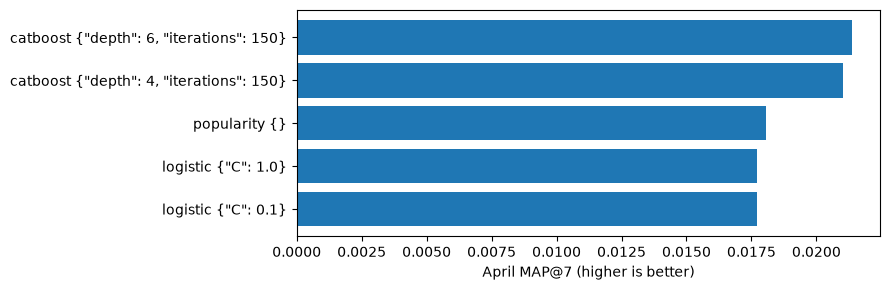

In [3]:
labels = comparison["model"] + " " + comparison["params"]
plt.figure(figsize=(9, 3))
plt.barh(labels, comparison["map_at_7"])
plt.gca().invert_yaxis()
plt.xlabel("April MAP@7 (higher is better)")
plt.tight_layout()
plt.show()

## May results

The model and threshold are fixed before May is evaluated. Report three populations, each with its own denominator. Classifier-selected customers include false positives.

In [4]:
display(pd.read_csv(report_dir / "three_scores.csv"))
stage = metrics["two_stage_test"]
gate = stage["classifier"]
display(pd.DataFrame([gate])[["precision", "recall", "coverage", "f1", "average_precision"]])
print(f"Gated MAP@7 over ALL customers: {stage['map_at_7_gated_all_customers']:.5f}")
print("Selected ranker:", metrics["selected_model"], metrics["selected_params"])

,population,customers,map_at_7
0,All customers (ungated),48474,0.023522
1,Actual acquiring customers (known afterward),1484,0.768328
2,Classifier-selected customers,1854,0.209956


,precision,recall,coverage,f1,average_precision
0,0.291802,0.364555,0.038247,0.324146,0.25817


Gated MAP@7 over ALL customers: 0.00803
Selected ranker: catboost {'depth': 6, 'iterations': 150}


In [5]:
test = metrics["selected_model_test"]
ceiling = test["customers_with_additions"] / test["customers"]
print(f"Customers with acquisitions: {test['customers_with_additions']:,} / {test['customers']:,}")
print(f"Maximum overall MAP@7: {ceiling:.5f}")
print(f"Ranker MAP@7: {test['map_at_7']:.5f} ({test['map_at_7']/ceiling:.1%} of the ceiling)")
print(f"Popularity MAP@7: {metrics['popularity_test']['map_at_7']:.5f}")

Customers with acquisitions: 1,484 / 48,474
Maximum overall MAP@7: 0.03061
Ranker MAP@7: 0.02352 (76.8% of the ceiling)
Popularity MAP@7: 0.01969


The selected-group MAP is not an improvement over the full-population MAP: their denominators differ. Counting abstentions as zero over everyone, the gate can only preserve or reduce the score for a fixed ranker. Its benefit would be fewer irrelevant offers.

The classifier predicts acquisition, not response to an offer. F1 is an initial threshold policy; an offer budget or cost model would be needed for deployment decisions.

## Ranker feature importance

Importance comes from the strongest learned ranker. CatBoost uses its fitted feature importance; logistic regression uses absolute coefficients. Neither is a causal explanation. Buyer-classifier importance is shown separately in its EDA.

Importance model: catboost


,feature,importance
0,product,34.473878
1,is_active_customer,18.207979
2,relationship_month_start,11.719174
3,age,7.855711
4,tenure_months,5.332932
5,joining_channel,4.307906
6,has_payroll_account,3.725531
7,has_current_account,3.632592
8,customer_segment,2.796355
9,snapshot_month,1.644590


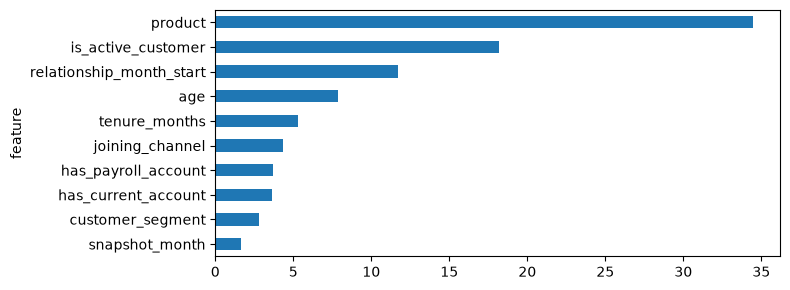

In [6]:
importance = pd.read_csv(report_dir / "feature_importance.csv")
print("Importance model:", metrics["feature_importance_model"])
display(importance.head(10))
importance.head(10).sort_values("importance").plot.barh(x="feature", y="importance", legend=False, figsize=(8, 3))
plt.tight_layout()
plt.show()

## Saved models

After evaluation, refit both models through May while keeping the April-selected parameters and threshold. The saved artifact is for June predictions; the May scores above belong to the earlier fits.

The API returns `should_recommend` and up to seven unowned products. It returns an empty list when the classifier abstains. Product ranking scores use sampled negatives and are not calibrated probabilities.

See the [README](../README.md) for FastAPI, Docker, tests, and [recorded HTTP examples](../reports/deployment.md). This is one historical holdout month; rolling validation and a separate cold-start evaluation remain future work.

## History features and learning-to-rank

A separate experiment compares the existing classifier with CatBoostRanker and LightGBM LambdaRank, each with and without history features. Run it from the project root:

```sh
uv run python experiments/ranking.py
```

Use the same 50,000 customers and seed 42. Each validation month (February, March, April) uses the preceding six target months for fitting. Settings are fixed in advance: 150 trees, depth 6 for CatBoost, and 31 leaves for LightGBM. Compare the mean of the three monthly MAP@7 scores.

History features describe information already observed at the feature month: owned product count, available history length, recent acquisitions/removals, and activity changes. Three-month windows reset after gaps or unknown holdings. Recency is time since an **observed** acquisition; acquisitions in unobserved months remain unknown.

For rankers, a group contains the unowned products for one customer-month. Groups with all-zero or all-one labels provide no ordering signal, so fitting uses mixed-label groups with all their eligible products. The classifier instead uses all acquisitions and a uniform 3% sample of eligible negatives, as before. Evaluation includes all customer groups and eligible products for every model.

CatBoost uses `YetiRank:mode=MAP;top=7`; LightGBM uses LambdaRank with an NDCG objective. Both are evaluated with our same AP@7 calculation. See [CatBoost ranking objectives](https://catboost.ai/docs/en/concepts/loss-functions-ranking) and [LightGBM Ranker](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMRanker.html).

The strongest rolling-validation model is then compared on May as an **exploratory reference**, since May has already been examined. The experiment does not replace the serving artifact. History-based serving would also need historical inputs; the current API accepts one snapshot.

In [ ]:
ranking_folds = pd.read_csv(report_dir / "ranking_folds.csv")
ranking_comparison = pd.read_csv(report_dir / "ranking_comparison.csv")
display(ranking_comparison)
display(ranking_folds.pivot(index=["model", "history"], columns="validation_month", values="map_at_7"))
ranking_metrics = json.loads((report_dir / "ranking_metrics.json").read_text())
display(pd.DataFrame([ranking_metrics]).drop(columns=["classifier"]))

In [ ]:
ranking_comparison = ranking_comparison.sort_values("mean_map_at_7")
labels = ranking_comparison["model"] + ranking_comparison["history"].map({True: " + history", False: ""})
plt.figure(figsize=(9, 4))
plt.barh(labels, ranking_comparison["mean_map_at_7"])
plt.xlabel("Mean February–April MAP@7")
plt.tight_layout()
plt.savefig(report_dir / "ranking_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

**Result:** LightGBM LambdaRank with history has the best mean February–April MAP@7. Ranking models beat the classifier in all three months; history alone gives a much smaller gain. See [the experiment summary](../reports/ranking_results.md) for the three May ranking scores and limitations. The production API and its saved model remain unchanged.